In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

from scipy.interpolate import griddata
from skimage.restoration import inpaint

In [2]:
## load map database
path_to_db = '/mnt/d/data/magnification_maps/masterlist.db'
db = sqlite3.connect(path_to_db)
## select maps
# df = pd.read_sql_query("SELECT * FROM maps WHERE NOT (s = 0.95) AND (kappa BETWEEN 0.13 AND 0.5) AND (gamma BETWEEN 0.13 AND 0.5)", db)
df = pd.read_sql_query("SELECT * FROM maps WHERE 1/((1-kappa)*(1-kappa) - gamma*gamma) > 0 AND kappa < 1.0 AND kappa > 0.0", db)

In [3]:
df[(df['kappa']==0.06) & (df['gamma']==0.2)].sort_values('s')

,index,id,kappa,gamma,s
16516,38864,14733,0.06,0.2,0.00
24229,56993,14734,0.06,0.2,0.10
1850,4346,14735,0.06,0.2,0.20
9452,22254,14736,0.06,0.2,0.30
32038,75492,14737,0.06,0.2,0.40
6326,14830,14738,0.06,0.2,0.50
16623,39143,14739,0.06,0.2,0.60
32018,75448,14740,0.06,0.2,0.70
9454,22260,14741,0.06,0.2,0.80
1829,4293,14742,0.06,0.2,0.90


In [4]:
np.unique(df[(df['kappa']==0.06)]['gamma'])

array([0.2 , 0.21, 0.22, 0.85, 0.86, 0.87, 0.88, 0.89, 0.9 , 0.91, 0.92,
       0.93])

In [5]:
Nbins = 400

kappa_masterlist = np.unique(df['kappa']).tolist()
gamma_masterlist = np.unique(df['gamma']).tolist()
s_masterlist     = (np.arange(0, 100, 1)).tolist()

data = np.zeros((Nbins, len(kappa_masterlist), len(gamma_masterlist), len(s_masterlist)))
data[:] = np.nan

for kappa in kappa_masterlist:
    gamma_list = np.unique(df[df['kappa']==kappa]['gamma'])
    kappa_index = kappa_masterlist.index(kappa)
    for gamma in gamma_list:
        gamma_index = gamma_masterlist.index(gamma)
        df_sub = df[(df['kappa']==kappa) & (df['gamma']==gamma)]
        df_sub.sort_values('s', inplace=True)
        df_sub.drop_duplicates('s', inplace=True)
        mapids = df_sub['id'].values
        Nmaps = len(mapids)
        ss = df_sub['s'].values*100
        
        points = np.zeros((Nbins*Nmaps, 2)) ## points only for log10_mu and s, since kappa and gamma are constant.
        values = np.zeros(Nbins*Nmaps)      ## p_mu
        
        for i, (mapid, s) in enumerate(zip(mapids, ss)):
            mu, p_mu = np.loadtxt('/mnt/d/data/imf_with_doubles/test/' + str(mapid) +'.dat').T
            log10_mu = np.log10(mu)
            points[Nbins*i:Nbins*(i+1), 0] = log10_mu
            points[Nbins*i:Nbins*(i+1), 1] = np.asarray(s)
            values[Nbins*i:Nbins*(i+1)] = p_mu
        
        s_new = np.arange(np.min(ss), np.max(ss)+1, 1)
        new_points = np.vstack([np.tile(log10_mu, len(s_new)), np.repeat(s_new, Nbins)]).T
        new_values = griddata(points, values, new_points, method='cubic')
        
        for i, s in enumerate(s_new):
            s_index = s_masterlist.index(s)
            data[:, kappa_index, gamma_index, s_index] = new_values[i*Nbins:(i+1)*Nbins]

/tmp/ipykernel_601/2828880236.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sub.sort_values('s', inplace=True)
/tmp/ipykernel_601/2828880236.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sub.drop_duplicates('s', inplace=True)


In [6]:
mask = np.isnan(data)

for i, kappa in enumerate(kappa_masterlist):
    for j, gamma in enumerate(gamma_masterlist):
        if np.abs((1-kappa)**2 - gamma**2) == 0:
            mask[:, i, j, :] = False
            continue
        if 1/((1-kappa)*(1-kappa) - gamma*gamma) < 0:
            mask[:, i, j, :] = False

data_defect = np.zeros_like(data)
data_defect = data * ~mask
data_defect = np.nan_to_num(data_defect)

data_inpaint = np.zeros_like(data)

#data_inpaint = inpaint.inpaint_biharmonic(data_defect, mask, split_into_regions=True)

for i in range(Nbins):
    for j in range(len(s_masterlist)):
        data_inpaint[i, :, :, j] = inpaint.inpaint_biharmonic(data_defect[i, :, :, j].copy(), mask[i, :, :, j].copy())

In [7]:
data[data<0] = 0
data_inpaint[data_inpaint<0] = 0
np.save('/mnt/d/data/imf_with_doubles/test/mpd_grid.npy', data)
np.save('/mnt/d/data/imf_with_doubles/test/mpd_grid_inpaint.npy', data_inpaint)

In [8]:
np.savetxt('microlensing_mpd/kappa_list.txt', kappa_masterlist)
np.savetxt('microlensing_mpd/gamma_list.txt', gamma_masterlist)
np.savetxt('microlensing_mpd/s_list.txt', s_masterlist)
np.savetxt('microlensing_mpd/log10_mu.txt', log10_mu)

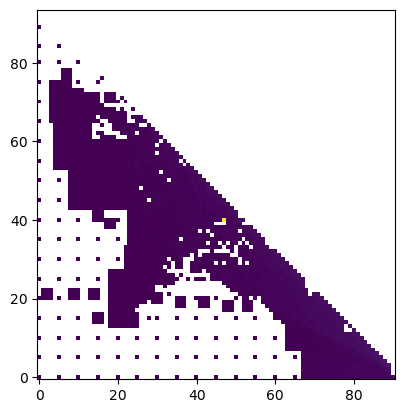

In [22]:
plt.imshow(data[200, :, :, 99].T, origin='lower')

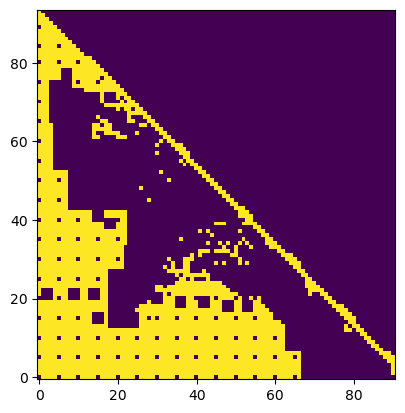

In [23]:
plt.imshow(mask[200, :, :, 99].T, origin='lower')

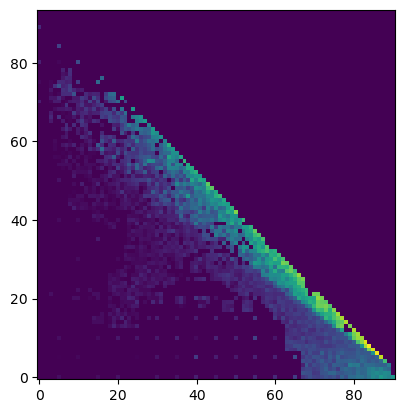

In [25]:
plt.imshow(data_defect[185, :, :, 99].T, origin='lower')

In [28]:
aux1 = data_defect[185, :, :, 99].copy()
aux2 = mask[185, :, :, 99].copy()
aux3 = inpaint.inpaint_biharmonic(aux1, aux2)

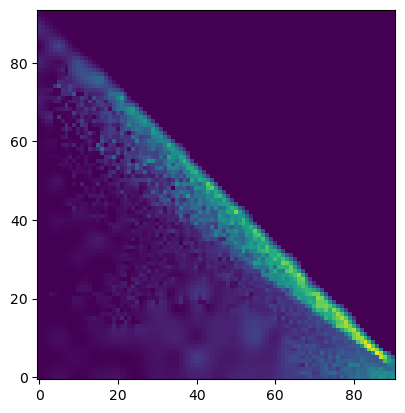

In [29]:
plt.imshow(aux3.T, origin='lower')

In [72]:
10**log10_mu[85]

1.049615